In [1]:
# Basic libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("/content/customer_segment_data.csv")
print(df.shape)
df.head()


(1000, 5)


,Customer_Age,Annual_Income,Credit_Score,Loan_Amount,Investment
0,56,125186,414,8239,6439
1,69,54674,622,7710,47964
2,46,55854,339,22384,48062
3,32,66271,339,22038,35563
4,60,93688,588,41846,34964


In [3]:
# Take only numeric columns (e.g. Age, Income, Credit_Score, etc.)
X = df.select_dtypes(include=[np.number])

# Handle missing values (if any)
X = X.fillna(X.median())

# Standardize the data (important for clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [4]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(df['Cluster'].value_counts())


Cluster sizes:
Cluster
0    270
3    250
1    245
2    235
Name: count, dtype: int64


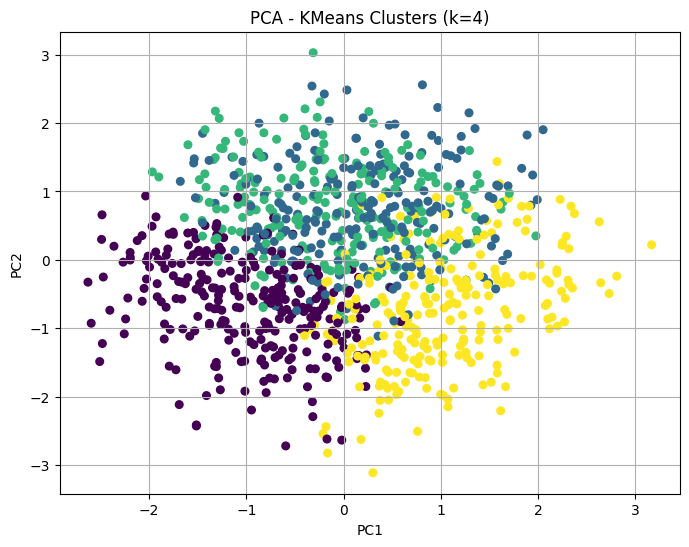

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
plt.title(f"PCA - KMeans Clusters (k={k})")
plt.scatter(X_pca[:,0], X_pca[:,1], c=df['Cluster'], cmap='viridis', s=30)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()


In [6]:
cluster_summary = df.groupby('Cluster').mean()
cluster_summary


,Customer_Age,Annual_Income,Credit_Score,Loan_Amount,Investment
Cluster,,,,,
0,47.688889,118597.462963,503.518519,14454.870370,25368.170370
1,39.534694,86252.987755,647.771429,32944.955102,38894.000000
2,41.463830,47844.625532,596.782979,13639.217021,24969.102128
3,46.052000,82036.768000,560.080000,37707.368000,12235.408000
